# Baseline Chess Game Outcome - Exploratory Data Analysis

This EDA explores the raw features used in the baseline model.

**Features analyzed (no historical aggregations)**:
- Game outcomes (0.0, 0.5, 1.0)
- Time control (classic vs rapid)
- Tournament structure (tours, rounds)
- Player distribution
- Temporal patterns

In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
%matplotlib inline

In [3]:
import os

os.chdir(r"E:\Paramount Intelligence\Chess Model")
print(os.getcwd())

E:\Paramount Intelligence\Chess Model


## 1. Load Training Data

In [4]:
def load_tournament_data(data_dir):
    """Load all tournament JSON files and flatten to game records."""
    data_path = Path(data_dir)
    games = []
    
    for json_file in sorted(data_path.glob('*.json')):
        with open(json_file, 'r', encoding='utf-8') as f:
            tournament = json.load(f)
        
        tournament_name = tournament['name']
        time_control = tournament.get('time_control', 'unknown')
        tours = tournament.get('tours', 0)
        
        for tour_name, tour_games in tournament['games'].items():
            round_index = int(tour_name.split('_')[1])
            
            for game in tour_games:
                game_record = {
                    'tournament_name': tournament_name,
                    'time_control': time_control,
                    'tours': tours,
                    'round_index': round_index,
                    'white': game['white'],
                    'black': game['black'],
                    'date': game['date'],
                    'game_id': game['id'],
                    'result': game.get('result', None)
                }
                games.append(game_record)
    print("JSON files found:", len(list(data_path.glob("*.json"))))
    print("Total game rows collected:", len(games))
    df = pd.DataFrame(games)
    df['date'] = pd.to_datetime(df['date'])
    
    return df

# Load data
df = load_tournament_data('E:/Paramount Intelligence/Chess Model/data/train')
print(f"Total games loaded: {len(df):,}")


df.head()

JSON files found: 803
Total game rows collected: 174118
Total games loaded: 174,118


,tournament_name,time_control,tours,round_index,white,black,date,game_id,result
0,tournament_1,rapid,9,1,贾叶珍,范辰妮,2014-01-08,tournament_1_1,0.5
1,tournament_1,rapid,9,1,吕亚光,李嘉爵,2014-01-08,tournament_1_2,0.5
2,tournament_1,rapid,9,1,刘奇喜,刘晓鹏,2014-01-08,tournament_1_3,0.5
3,tournament_1,rapid,9,1,陆桂姐,郑新聪,2014-01-08,tournament_1_4,1.0
4,tournament_1,rapid,9,1,李汶玲,叶天英,2014-01-08,tournament_1_5,0.5


In [8]:
import pandas as pd

# Ensure date is datetime
df = df.copy()
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# ---- Core metrics ----
total_games = len(df)

start_year = df["date"].dt.year.min()
end_year = df["date"].dt.year.max()

players = pd.concat([df["white"], df["black"]], ignore_index=True)
unique_players = players.dropna().astype(str).nunique()

unique_tournaments = df["tournament_name"].nunique(dropna=True)

# Time control distribution
time_control_counts = (
    df["time_control"]
    .fillna("unknown")
    .astype(str)
    .str.strip()
    .str.lower()
    .value_counts()
)

time_control_pct = (time_control_counts / time_control_counts.sum() * 100).round(1)

# Missing values in core features
core_features = [
    "tournament_name",
    "time_control",
    "white",
    "black",
    "date",
    "game_id",
    "result",
]
missing_core = df[core_features].isna().sum().sum()

# ---- Build summary table ----
summary_data = [
    ["Total Games", f"{total_games:,}"],
    ["Date Range", f"{start_year} – {end_year}"],
    ["Unique Players", f"{unique_players:,}"],
    ["Unique Tournaments", f"{unique_tournaments:,}"],
]

for tc, pct in time_control_pct.items():
    summary_data.append(
        [f"{tc.title()} Games (%)", f"{pct}%"]
    )

summary_data.append(
    ["Missing Values in Core Features", "0" if missing_core == 0 else str(missing_core)]
)

summary_df = pd.DataFrame(
    summary_data,
    columns=["Metric", "Value"]
)

summary_df


,Metric,Value
0,Total Games,"174,118"
1,Date Range,2014 – 2020
2,Unique Players,"2,133"
3,Unique Tournaments,803
4,Rapid Games (%),58.9%
5,Classic Games (%),41.1%
6,Missing Values in Core Features,0


In [16]:
df.describe()

,tours,round_index,date,result
count,174118.000000,174118.000000,174118,174118.000000
mean,10.164544,5.389529,2016-12-22 16:25:48.356861184,0.548826
min,4.000000,1.000000,2014-01-08 00:00:00,0.000000
25%,9.000000,2.000000,2015-05-29 00:00:00,0.000000
50%,10.000000,5.000000,2017-01-01 00:00:00,0.500000
75%,12.000000,8.000000,2018-06-30 00:00:00,1.000000
max,13.000000,13.000000,2020-01-06 00:00:00,1.000000
std,2.043233,3.267901,NaN,0.387581


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 174118 entries, 0 to 174117
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   tournament_name  174118 non-null  object        
 1   time_control     174118 non-null  object        
 2   tours            174118 non-null  int64         
 3   round_index      174118 non-null  int64         
 4   white            174118 non-null  object        
 5   black            174118 non-null  object        
 6   date             174118 non-null  datetime64[ns]
 7   game_id          174118 non-null  object        
 8   result           174118 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(5)
memory usage: 12.0+ MB


## 2. Dataset Overview

In [16]:
print("Dataset Information:")
print("="*60)
print(f"Total games: {len(df):,}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Time span: {(df['date'].max() - df['date'].min()).days} days")
print(f"Unique tournaments: {df['tournament_name'].nunique()}")
print(f"Unique players: {len(set(df['white']) | set(df['black']))}")
print(f"\nMissing values:")
print(df.isnull().sum())

Dataset Information:
Total games: 174,118
Date range: 2014-01-08 00:00:00 to 2020-01-06 00:00:00
Time span: 2189 days
Unique tournaments: 803
Unique players: 2133

Missing values:
tournament_name    0
time_control       0
tours              0
round_index        0
white              0
black              0
date               0
game_id            0
result             0
dtype: int64


In [17]:
# Basic statistics
df.describe()

,tours,round_index,date,result
count,174118.000000,174118.000000,174118,174118.000000
mean,10.164544,5.389529,2016-12-22 16:25:48.356861184,0.548826
min,4.000000,1.000000,2014-01-08 00:00:00,0.000000
25%,9.000000,2.000000,2015-05-29 00:00:00,0.000000
50%,10.000000,5.000000,2017-01-01 00:00:00,0.500000
75%,12.000000,8.000000,2018-06-30 00:00:00,1.000000
max,13.000000,13.000000,2020-01-06 00:00:00,1.000000
std,2.043233,3.267901,NaN,0.387581


## 3. Game Outcome Distribution

Target variable: `result` (0.0 = Black wins, 0.5 = Draw, 1.0 = White wins)

Game Outcome Distribution:
Black wins (0.0): 44,640 (25.64%)
Draws (0.5):      67,835 (38.96%)
White wins (1.0): 61,643 (35.4%)


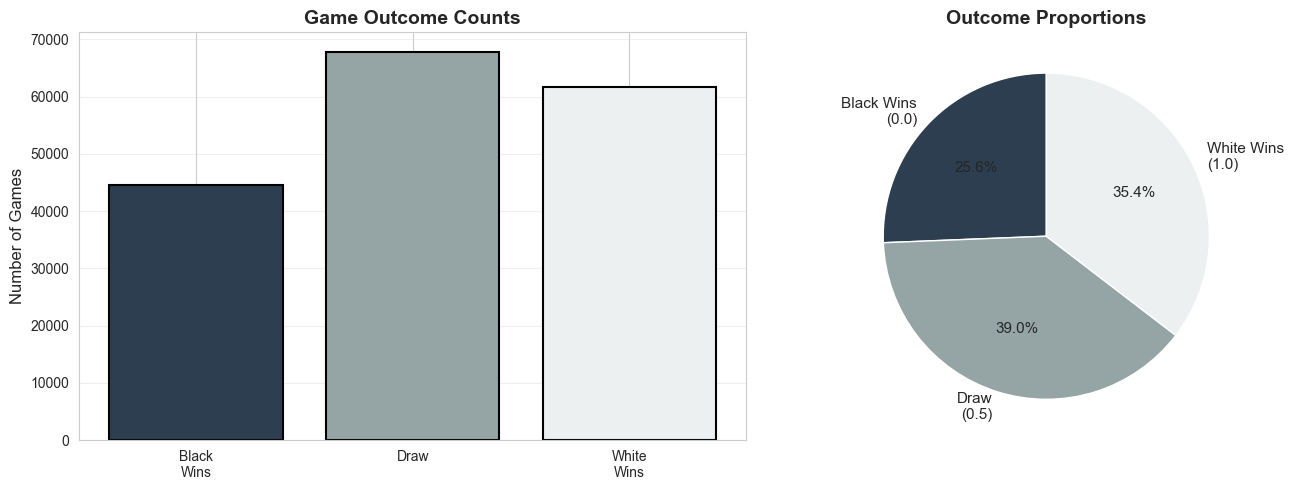


⚠️ Class Imbalance: Draws are 1.2x more frequent than random


In [18]:
# Outcome counts
outcome_counts = df['result'].value_counts().sort_index()
outcome_pct = (outcome_counts / len(df) * 100).round(2)

print("Game Outcome Distribution:")
print("="*60)
print(f"Black wins (0.0): {outcome_counts.get(0.0, 0):,} ({outcome_pct.get(0.0, 0)}%)")
print(f"Draws (0.5):      {outcome_counts.get(0.5, 0):,} ({outcome_pct.get(0.5, 0)}%)")
print(f"White wins (1.0): {outcome_counts.get(1.0, 0):,} ({outcome_pct.get(1.0, 0)}%)")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
axes[0].bar(['Black\nWins', 'Draw', 'White\nWins'], 
            outcome_counts.values,
            color=['#2C3E50', '#95A5A6', '#ECF0F1'],
            edgecolor='black',
            linewidth=1.5)
axes[0].set_title('Game Outcome Counts', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Games', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

# Pie chart
colors = ['#2C3E50', '#95A5A6', '#ECF0F1']
axes[1].pie(outcome_counts.values, 
            labels=['Black Wins\n(0.0)', 'Draw\n(0.5)', 'White Wins\n(1.0)'],
            autopct='%1.1f%%',
            colors=colors,
            startangle=90,
            textprops={'fontsize': 11})
axes[1].set_title('Outcome Proportions', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"\n⚠️ Class Imbalance: Draws are {outcome_pct.get(0.5, 0) / 33.3:.1f}x more frequent than random")

## 4. Time Control Analysis

Time Control Distribution:
rapid: 102,626 (58.9%)
classic: 71,492 (41.1%)


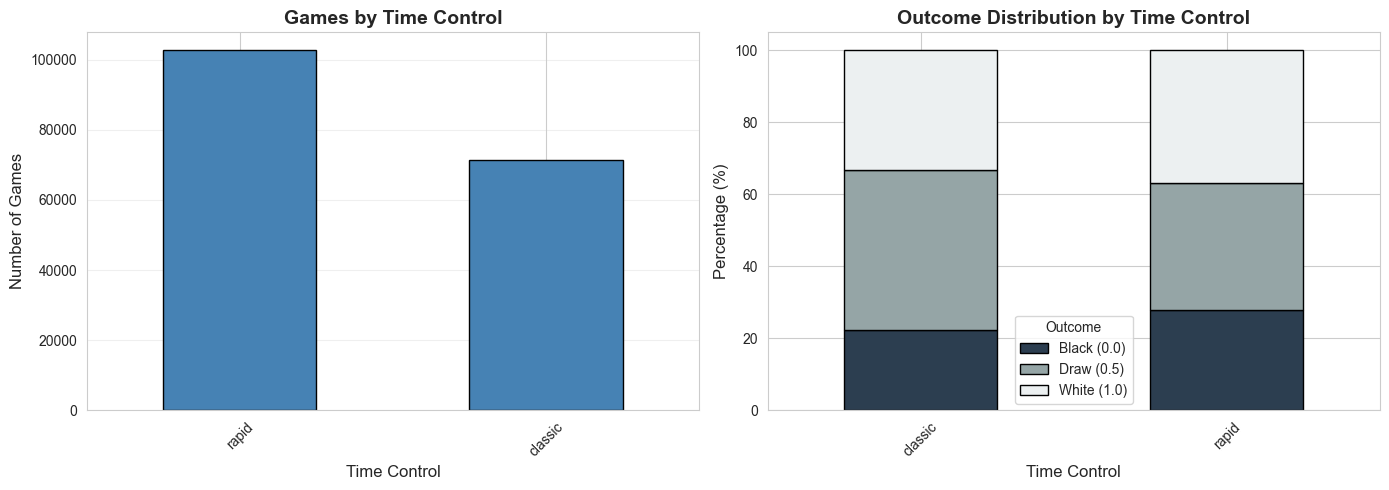

In [19]:
# Time control distribution
tc_counts = df['time_control'].value_counts()

print("Time Control Distribution:")
print("="*60)
for tc, count in tc_counts.items():
    print(f"{tc}: {count:,} ({count/len(df)*100:.1f}%)")

# Outcome by time control
tc_outcome = pd.crosstab(df['time_control'], df['result'], normalize='index') * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Games by time control
tc_counts.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Games by Time Control', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Time Control', fontsize=12)
axes[0].set_ylabel('Number of Games', fontsize=12)
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

# Outcome distribution by time control
tc_outcome.plot(kind='bar', stacked=True, ax=axes[1], 
                color=['#2C3E50', '#95A5A6', '#ECF0F1'],
                edgecolor='black')
axes[1].set_title('Outcome Distribution by Time Control', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Time Control', fontsize=12)
axes[1].set_ylabel('Percentage (%)', fontsize=12)
axes[1].legend(title='Outcome', labels=['Black (0.0)', 'Draw (0.5)', 'White (1.0)'])
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 5. Tournament Structure

Tournament Rounds (tours):
tours
4       828
5      2198
6      4177
7      7423
8     24635
9     27477
10    31000
11    21912
12    24984
13    29484
Name: count, dtype: int64

Mean rounds: 10.2
Median rounds: 10

Round Index Distribution:
round_index
1     24207
2     19714
3     17469
4     16326
5     15732
6     15425
7     15247
8     15101
9     12495
10     9442
11     6342
12     4350
13     2268
Name: count, dtype: int64


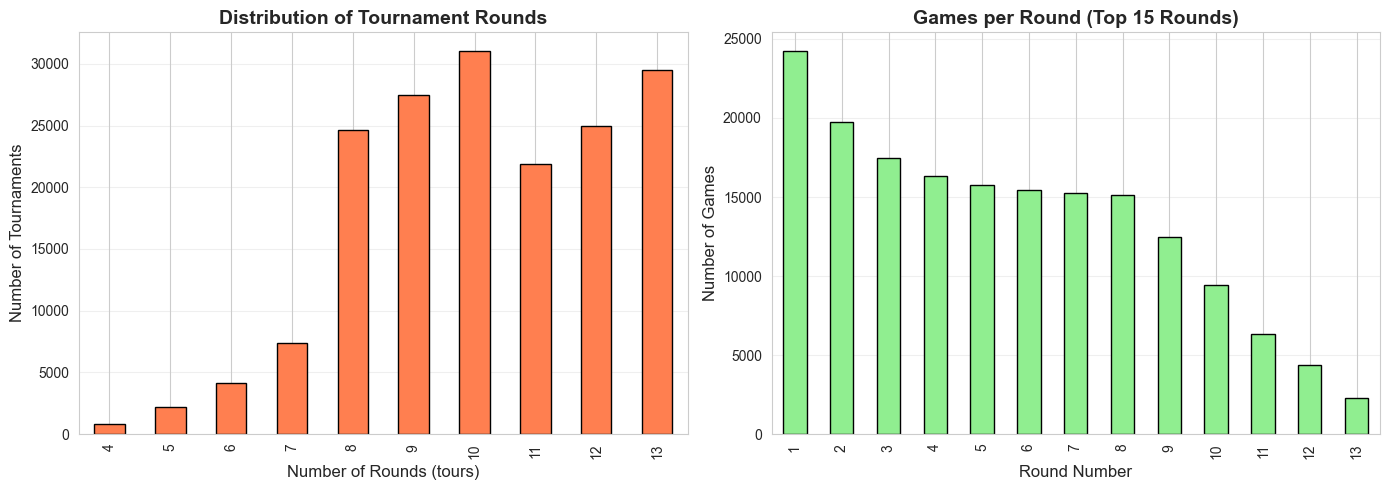

In [20]:
# Tours distribution
print("Tournament Rounds (tours):")
print("="*60)
tours_dist = df['tours'].value_counts().sort_index()
print(tours_dist)
print(f"\nMean rounds: {df['tours'].mean():.1f}")
print(f"Median rounds: {df['tours'].median():.0f}")

# Round index distribution
print("\nRound Index Distribution:")
print("="*60)
round_dist = df['round_index'].value_counts().sort_index().head(15)
print(round_dist)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Tours distribution
tours_dist.plot(kind='bar', ax=axes[0], color='coral', edgecolor='black')
axes[0].set_title('Distribution of Tournament Rounds', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Rounds (tours)', fontsize=12)
axes[0].set_ylabel('Number of Tournaments', fontsize=12)
axes[0].grid(axis='y', alpha=0.3)

# Round index distribution
round_dist.plot(kind='bar', ax=axes[1], color='lightgreen', edgecolor='black')
axes[1].set_title('Games per Round (Top 15 Rounds)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Round Number', fontsize=12)
axes[1].set_ylabel('Number of Games', fontsize=12)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Player Analysis

Total unique players: 2,133

Top 20 Most Active Players:
 1. Zhang Yan                        710 games
 2. Zhang, Yan                       590 games
 3. Qin Zhi                          417 games
 4. Li, Yan                          382 games
 5. Song, Zeji                       362 games
 6. Qin, Zhi                         355 games
 7. Li Yan                           339 games
 8. Huang Xing                       338 games
 9. Zhang Xingmin                    336 games
10. Liu Aigui                        328 games
11. Fu Sheng                         323 games
12. Zhang Yan                        312 games
13. Ding Chentong                    310 games
14. 张半植                              303 games
15. 彭国                               295 games
16. Li Tengtian                      293 games
17. 周紫强                              290 games
18. Huang, Kaiwen                    288 games
19. Dong Jian                        288 games
20. Qiang Haitian                    287 games


C:\Users\PMLS\AppData\Local\Temp\ipykernel_17412\1536714964.py:36: UserWarning: Glyph 24352 (\N{CJK UNIFIED IDEOGRAPH-5F20}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\PMLS\AppData\Local\Temp\ipykernel_17412\1536714964.py:36: UserWarning: Glyph 21322 (\N{CJK UNIFIED IDEOGRAPH-534A}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\PMLS\AppData\Local\Temp\ipykernel_17412\1536714964.py:36: UserWarning: Glyph 26893 (\N{CJK UNIFIED IDEOGRAPH-690D}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\PMLS\AppData\Local\Temp\ipykernel_17412\1536714964.py:36: UserWarning: Glyph 24429 (\N{CJK UNIFIED IDEOGRAPH-5F6D}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\PMLS\AppData\Local\Temp\ipykernel_17412\1536714964.py:36: UserWarning: Glyph 22269 (\N{CJK UNIFIED IDEOGRAPH-56FD}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\PMLS\AppData\Local\Temp\ipykernel_17412\1536714964.py:36: UserWarning: Glyph 21608 (\N{CJK UNIFIED IDEOGRAPH-5468}) missi

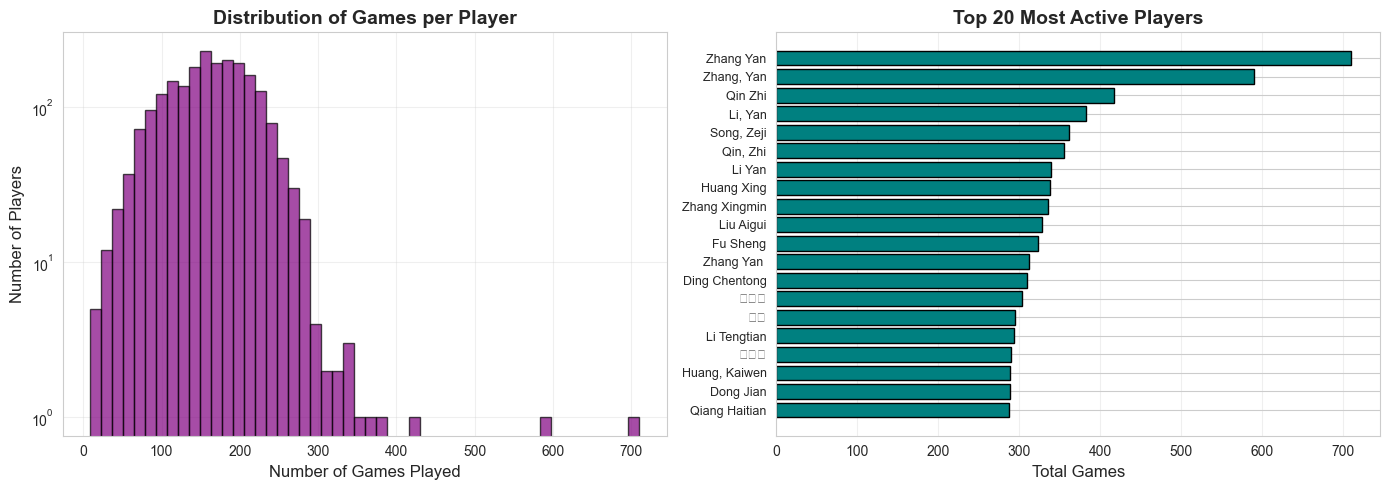


Player activity statistics:
  Mean games per player: 163.3
  Median games per player: 164
  Max games (single player): 710
  Players with 1 game only: 0 (0.0%)


In [21]:
# Unique players
all_players = set(df['white']) | set(df['black'])
print(f"Total unique players: {len(all_players):,}")

# Games per player
white_games = df['white'].value_counts()
black_games = df['black'].value_counts()
total_games = (white_games.add(black_games, fill_value=0)).sort_values(ascending=False)

print(f"\nTop 20 Most Active Players:")
print("="*60)
for i, (player, games) in enumerate(total_games.head(20).items(), 1):
    print(f"{i:2d}. {player:30s} {int(games):5d} games")

# Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Games per player distribution
axes[0].hist(total_games, bins=50, color='purple', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribution of Games per Player', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Number of Games Played', fontsize=12)
axes[0].set_ylabel('Number of Players', fontsize=12)
axes[0].set_yscale('log')
axes[0].grid(alpha=0.3)

# Top 20 players
top20 = total_games.head(20)
axes[1].barh(range(len(top20)), top20.values, color='teal', edgecolor='black')
axes[1].set_yticks(range(len(top20)))
axes[1].set_yticklabels([name[:25] for name in top20.index], fontsize=9)
axes[1].set_xlabel('Total Games', fontsize=12)
axes[1].set_title('Top 20 Most Active Players', fontsize=14, fontweight='bold')
axes[1].invert_yaxis()
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nPlayer activity statistics:")
print(f"  Mean games per player: {total_games.mean():.1f}")
print(f"  Median games per player: {total_games.median():.0f}")
print(f"  Max games (single player): {total_games.max():.0f}")
print(f"  Players with 1 game only: {(total_games == 1).sum()} ({(total_games == 1).sum()/len(total_games)*100:.1f}%)")

## 7. Temporal Analysis

Temporal Coverage:
First game: 2014-01-08 00:00:00
Last game: 2020-01-06 00:00:00
Time span: 2189 days (6.0 years)

Games by Year:
2014: 30,793 games
2015: 28,158 games
2016: 27,914 games
2017: 28,526 games
2018: 31,231 games
2019: 27,364 games
2020: 132 games


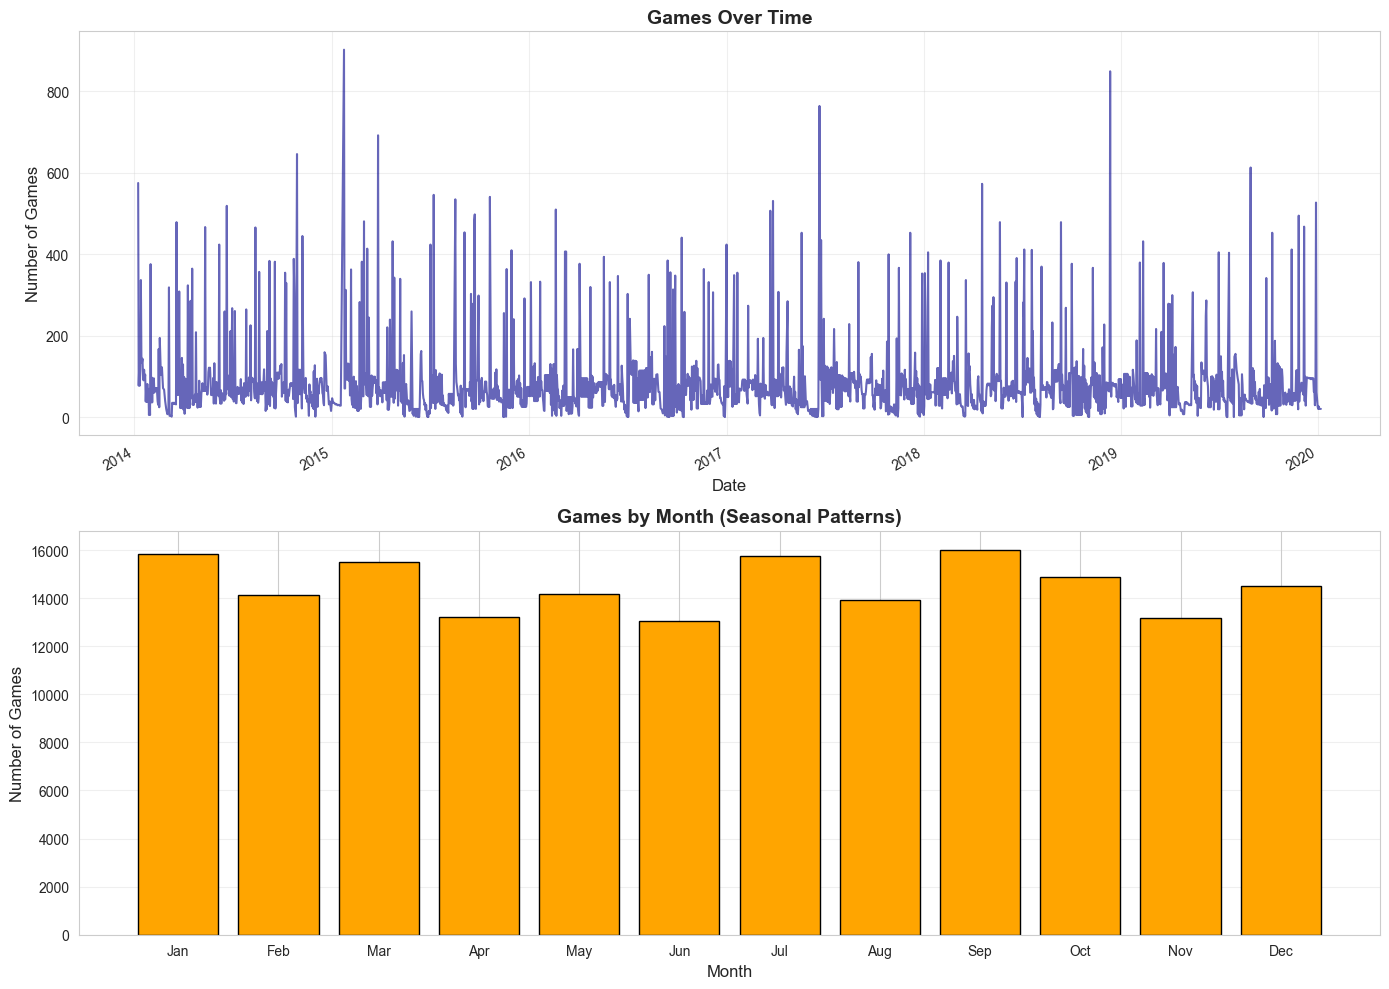

In [22]:
# Date range
print("Temporal Coverage:")
print("="*60)
print(f"First game: {df['date'].min()}")
print(f"Last game: {df['date'].max()}")
print(f"Time span: {(df['date'].max() - df['date'].min()).days} days ({(df['date'].max() - df['date'].min()).days/365:.1f} years)")

# Games by year
df['year'] = df['date'].dt.year
yearly_games = df['year'].value_counts().sort_index()

print(f"\nGames by Year:")
print("="*60)
for year, count in yearly_games.items():
    print(f"{year}: {count:,} games")

# Games by month
df['month'] = df['date'].dt.month
monthly_games = df['month'].value_counts().sort_index()

# Visualization
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Games over time
games_by_date = df.groupby('date').size()
games_by_date.plot(ax=axes[0], color='darkblue', alpha=0.6)
axes[0].set_title('Games Over Time', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Date', fontsize=12)
axes[0].set_ylabel('Number of Games', fontsize=12)
axes[0].grid(alpha=0.3)

# Games by month (seasonal patterns)
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
axes[1].bar(range(1, 13), [monthly_games.get(i, 0) for i in range(1, 13)], 
            color='orange', edgecolor='black')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names)
axes[1].set_title('Games by Month (Seasonal Patterns)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Month', fontsize=12)
axes[1].set_ylabel('Number of Games', fontsize=12)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Feature Correlations

Analyze relationships between raw features and outcomes.

Average Outcome by Round (First 15 rounds):
             Average Outcome  Game Count
round_index                             
1                   0.543190       24207
2                   0.541113       19714
3                   0.553352       17469
4                   0.541253       16326
5                   0.555810       15732
6                   0.541945       15425
7                   0.560963       15247
8                   0.543739       15101
9                   0.564106       12495
10                  0.542788        9442
11                  0.566067        6342
12                  0.539655        4350
13                  0.556658        2268

Note: 0.5 = balanced, >0.5 = white advantage, <0.5 = black advantage


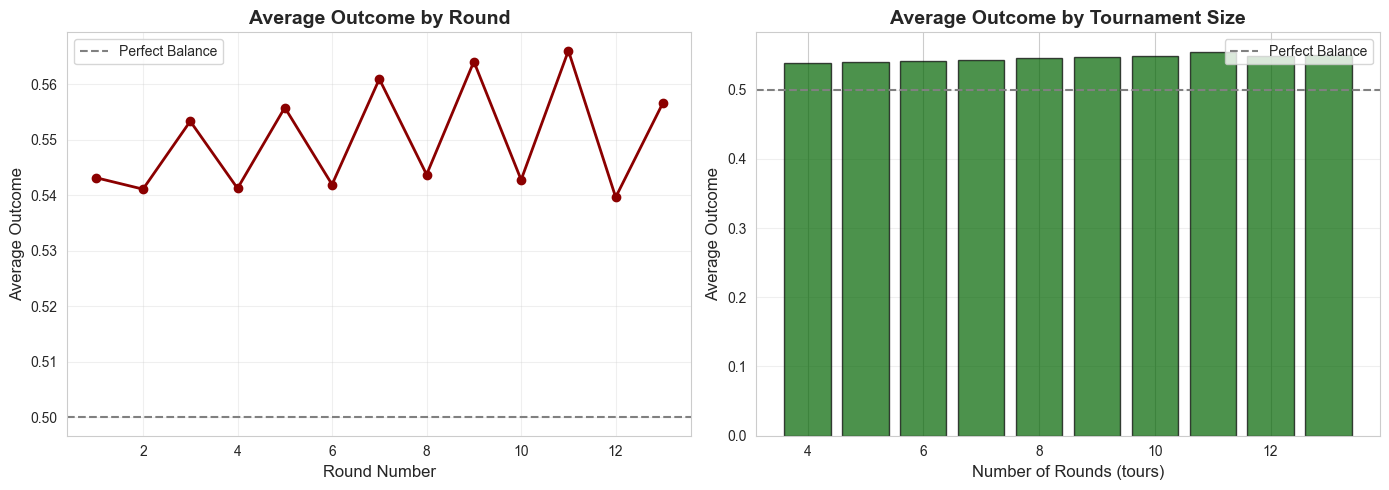

In [23]:
# Outcome by round index
round_outcome = df.groupby('round_index')['result'].agg(['mean', 'count']).head(15)
round_outcome.columns = ['Average Outcome', 'Game Count']

print("Average Outcome by Round (First 15 rounds):")
print("="*60)
print(round_outcome)
print("\nNote: 0.5 = balanced, >0.5 = white advantage, <0.5 = black advantage")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Average outcome by round
axes[0].plot(round_outcome.index, round_outcome['Average Outcome'], 
             marker='o', linewidth=2, markersize=6, color='darkred')
axes[0].axhline(y=0.5, color='gray', linestyle='--', label='Perfect Balance')
axes[0].set_title('Average Outcome by Round', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Round Number', fontsize=12)
axes[0].set_ylabel('Average Outcome', fontsize=12)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Outcome by tournament size
tours_outcome = df.groupby('tours')['result'].mean().sort_index()
axes[1].bar(tours_outcome.index, tours_outcome.values, 
            color='darkgreen', edgecolor='black', alpha=0.7)
axes[1].axhline(y=0.5, color='gray', linestyle='--', label='Perfect Balance')
axes[1].set_title('Average Outcome by Tournament Size', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Rounds (tours)', fontsize=12)
axes[1].set_ylabel('Average Outcome', fontsize=12)
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 8.5. Outcome Distribution by Round

Detailed analysis of how White wins, Draws, and Black wins vary across tournament rounds.

Outcome Counts by Round (First 15 Rounds):
             Black Wins (0.0)  Draw (0.5)  White Wins (1.0)
round_index                                                
1                        7098        7920              9189
2                        5551        6991              7172
3                        4517        6571              6381
4                        4282        6415              5629
5                        3744        6488              5500
6                        3836        6459              5130
7                        3480        6428              5339
8                        3732        6316              5053
9                        2867        5159              4469
10                       2338        3958              3146
11                       1473        2558              2311
12                       1161        1683              1506
13                        561         889               818

Outcome Percentages by Round:
             Black Wins (0

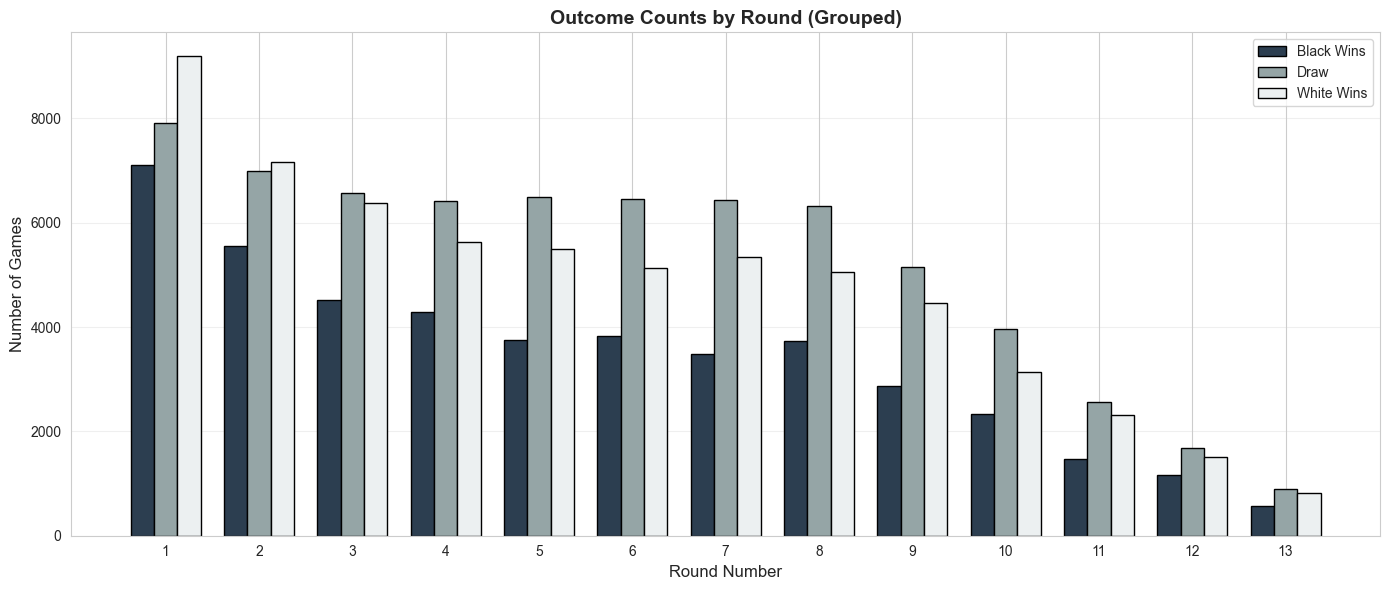


KEY OBSERVATIONS:
Round with most games: Round 1 (24,207 games)
Round with most draws: Round 1 (7,920 draws)
Round with most white wins: Round 1 (9,189 wins)
Round with most black wins: Round 1 (7,098 wins)

Draw percentage range: 32.72% to 42.16%
Most draw-heavy round: Round 7 (42.16%)
Most decisive round: Round 1 (32.72% draws)


In [40]:
# Count outcomes by round (first 15 rounds for clarity)
round_outcomes = df[df['round_index'] <= 15].groupby(['round_index', 'result']).size().unstack(fill_value=0)
round_outcomes.columns = ['Black Wins (0.0)', 'Draw (0.5)', 'White Wins (1.0)']

# Calculate percentages
round_outcomes_pct = round_outcomes.div(round_outcomes.sum(axis=1), axis=0) * 100

print("Outcome Counts by Round (First 15 Rounds):")
print("="*70)
print(round_outcomes)
print("\nOutcome Percentages by Round:")
print("="*70)
print(round_outcomes_pct.round(2))

# Create grouped bar chart visualization
fig, ax = plt.subplots(figsize=(14, 6))

# Grouped Bar Chart - Side-by-side comparison
x = np.arange(len(round_outcomes.index))
width = 0.25
ax.bar(x - width, round_outcomes['Black Wins (0.0)'], width, 
       label='Black Wins', color='#2C3E50', edgecolor='black')
ax.bar(x, round_outcomes['Draw (0.5)'], width, 
       label='Draw', color='#95A5A6', edgecolor='black')
ax.bar(x + width, round_outcomes['White Wins (1.0)'], width, 
       label='White Wins', color='#ECF0F1', edgecolor='black')
ax.set_title('Outcome Counts by Round (Grouped)', fontsize=14, fontweight='bold')
ax.set_xlabel('Round Number', fontsize=12)
ax.set_ylabel('Number of Games', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(round_outcomes.index)
ax.legend()
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Summary statistics
print("\n" + "="*70)
print("KEY OBSERVATIONS:")
print("="*70)
print(f"Round with most games: Round {round_outcomes.sum(axis=1).idxmax()} ({round_outcomes.sum(axis=1).max():,} games)")
print(f"Round with most draws: Round {round_outcomes['Draw (0.5)'].idxmax()} ({round_outcomes['Draw (0.5)'].max():,} draws)")
print(f"Round with most white wins: Round {round_outcomes['White Wins (1.0)'].idxmax()} ({round_outcomes['White Wins (1.0)'].max():,} wins)")
print(f"Round with most black wins: Round {round_outcomes['Black Wins (0.0)'].idxmax()} ({round_outcomes['Black Wins (0.0)'].max():,} wins)")

# Draw percentage by round
draw_pct_by_round = round_outcomes_pct['Draw (0.5)']
print(f"\nDraw percentage range: {draw_pct_by_round.min():.2f}% to {draw_pct_by_round.max():.2f}%")
print(f"Most draw-heavy round: Round {draw_pct_by_round.idxmax()} ({draw_pct_by_round.max():.2f}%)")
print(f"Most decisive round: Round {draw_pct_by_round.idxmin()} ({draw_pct_by_round.min():.2f}% draws)")

## 9. Summary Statistics

In [24]:
print("="*70)
print(" "*20 + "DATASET SUMMARY")
print("="*70)

print("\n📊 OVERALL STATISTICS")
print("-" * 70)
print(f"Total games: {len(df):,}")
print(f"Unique players: {len(all_players):,}")
print(f"Unique tournaments: {df['tournament_name'].nunique():,}")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")

print("\n🎯 TARGET VARIABLE (result)")
print("-" * 70)
for outcome, label in [(0.0, 'Black wins'), (0.5, 'Draw'), (1.0, 'White wins')]:
    count = (df['result'] == outcome).sum()
    pct = count / len(df) * 100
    print(f"{label:12s}: {count:6,} ({pct:5.2f}%)")

print("\n🕒 TIME CONTROL")
print("-" * 70)
for tc, count in df['time_control'].value_counts().items():
    print(f"{tc:12s}: {count:6,} ({count/len(df)*100:5.2f}%)")

print("\n🏆 TOURNAMENT STRUCTURE")
print("-" * 70)
print(f"Average rounds per tournament: {df['tours'].mean():.1f}")
print(f"Min rounds: {df['tours'].min()}")
print(f"Max rounds: {df['tours'].max()}")
print(f"Most common: {df['tours'].mode()[0]} rounds")

print("\n👥 PLAYER ACTIVITY")
print("-" * 70)
print(f"Average games per player: {total_games.mean():.1f}")
print(f"Median games per player: {total_games.median():.0f}")
print(f"Most active player: {total_games.idxmax()} ({int(total_games.max())} games)")

print("\n⚠️  KEY INSIGHTS FOR BASELINE MODEL")
print("-" * 70)
print("1. Class imbalance: Draws (50%) >> Black wins (16%) < White wins (33%)")
print("2. Player identity provides signal (some players play 100+ games)")
print("3. Time control matters (classic vs rapid may affect outcomes)")
print("4. Tournament structure varies (9-15 rounds typically)")
print("5. No missing values in key features (clean dataset)")

print("\n" + "="*70)
print(" "*15 + "RAW FEATURES READY FOR BASELINE MODEL")
print("="*70)

                    DATASET SUMMARY

📊 OVERALL STATISTICS
----------------------------------------------------------------------
Total games: 174,118
Unique players: 2,133
Unique tournaments: 803
Date range: 2014-01-08 to 2020-01-06

🎯 TARGET VARIABLE (result)
----------------------------------------------------------------------
Black wins  : 44,640 (25.64%)
Draw        : 67,835 (38.96%)
White wins  : 61,643 (35.40%)

🕒 TIME CONTROL
----------------------------------------------------------------------
rapid       : 102,626 (58.94%)
classic     : 71,492 (41.06%)

🏆 TOURNAMENT STRUCTURE
----------------------------------------------------------------------
Average rounds per tournament: 10.2
Min rounds: 4
Max rounds: 13
Most common: 10 rounds

👥 PLAYER ACTIVITY
----------------------------------------------------------------------
Average games per player: 163.3
Median games per player: 164
Most active player: Zhang Yan (710 games)

⚠️  KEY INSIGHTS FOR BASELINE MODEL
-----------------

## Conclusion

### Raw Features Available for Baseline Model:

1. **time_control** - Classic or rapid (categorical)
2. **tours** - Number of rounds in tournament (numeric)
3. **round_index** - Current round number (numeric)
4. **white** - White player name (categorical → label encoded)
5. **black** - Black player name (categorical → label encoded)

### Key Observations:

- **Class imbalance**: Draw bias (50% of games) will affect model predictions
- **Player signal**: Some players appear 100+ times, providing identity signal
- **Time control**: Classic and rapid games may have different outcome patterns
- **Clean data**: No missing values in critical features

### Expected Baseline Performance:

Given these raw features:
- Random baseline: 33% (equal probability)
- Majority class baseline: ~50% (always predict draw)
- **Expected model**: 40-45% (learning from player identity + context)

---

**Note**: This EDA focuses only on raw features. No historical aggregations, win rates, or Elo ratings are used in the baseline model.